# 01 · Exploratory analysis of Spanish peninsular electricity demand

This notebook looks at the hourly table built by `make data` (`data/processed/hourly.parquet`),
covering 2021-01-01 to 2026-10-31. It follows section 5 of `docs/DESIGN.md`.

**Reading guide.** Each section ends with what was found. The conclusions and the decisions
they lead to are collected at the end. All times are local (Europe/Madrid) unless stated;
the table itself is indexed in UTC. Hours are labelled by their start.

**Held-out data.** The test period (2025-11-01 onwards) is used here only for data-quality
checks and for describing REE's forecast. Modelling choices (thresholds, trends, features)
are read from the training and validation periods.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from loadforecast.config import PROCESSED_DIR, ROOT, load_config

pd.set_option("display.width", 160, "display.max_columns", 30, "display.float_format", "{:,.2f}".format)
plt.rcParams.update({"figure.dpi": 90, "savefig.dpi": 130, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.figsize": (11, 4)})
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet(PROCESSED_DIR / "hourly.parquet")
meta = json.loads((PROCESSED_DIR / "hourly.meta.json").read_text())
splits = load_config("backtest")["splits"]
df["year"] = df["local_date"].dt.year
df["month"] = df["local_date"].dt.month
df["gw"] = df["demand_mw"] / 1000
SEASONS = {12: "winter", 1: "winter", 2: "winter", 3: "spring", 4: "spring", 5: "spring",
           6: "summer", 7: "summer", 8: "summer", 9: "autumn", 10: "autumn", 11: "autumn"}
df["season"] = df["month"].map(SEASONS)
TEST_START = pd.Timestamp(splits["test"]["start"])
ok = df[~df["is_masked"]]                      # blackout days removed
dev = ok[ok["local_date"] < TEST_START]        # training + validation only
print(f"dataset hash {meta['hash']}  rows {len(df):,}  columns {df.shape[1]}")
print(f"{df.index[0]} -> {df.index[-1]} (UTC)")

dataset hash 9de7470fd446c749  rows 51,120  columns 50
2020-12-31 23:00:00+00:00 -> 2026-10-31 22:00:00+00:00 (UTC)


## 1. Data quality

In [2]:
print("Missing demand hours:", int(df["demand_mw"].isna().sum()), "of", len(df))
print("Gaps (consecutive missing hours):")
print(pd.DataFrame(meta["demand_gaps"]).to_string(index=False) if meta["demand_gaps"] else "  none")
print("\nObservations per hour (expected 6 at 10-minute and 12 at 5-minute resolution):")
print(df.groupby("year")["demand_n_obs"].value_counts().unstack(fill_value=0).to_string())
first5 = df.index[df["demand_n_obs"] == 12][0].tz_convert("Europe/Madrid")
print("\nFirst hour with 12 observations:", first5)
print("\nREE forecast missing hours:", int(df["ree_forecast_mw"].isna().sum()))
miss = df[df["ree_forecast_mw"].isna()].groupby("local_date").size()
print(miss.to_string() if len(miss) else "")

Missing demand hours: 0 of 51120
Gaps (consecutive missing hours):
  none

Observations per hour (expected 6 at 10-minute and 12 at 5-minute resolution):
demand_n_obs    6     12
year                    
2021          8760     0
2022          3428  5332
2023             0  8760
2024             0  8784
2025             0  8760
2026             0  7296

First hour with 12 observations: 2022-05-23 21:00:00+02:00

REE forecast missing hours: 0



In [3]:
print(f"Demand range: {df['demand_mw'].min():,.0f} to {df['demand_mw'].max():,.0f} MW")
print("Lowest hours:")
print(df.nsmallest(6, "demand_mw")[["local_date", "local_hour", "demand_mw", "is_masked"]].to_string())
print("\nHighest hours:")
print(df.nlargest(4, "demand_mw")[["local_date", "local_hour", "demand_mw", "temp_obs"]].to_string())
spikes = df[df["demand_spike"]]
print(f"\nHours flagged as spikes (robust z-score of the hourly change above 8): {len(spikes)}")
print(spikes.groupby("local_date").size().rename("flagged hours").to_string())

Demand range: 328 to 41,829 MW
Lowest hours:
                          local_date  local_hour  demand_mw  is_masked
time_utc                                                              
2025-04-28 11:00:00+00:00 2025-04-28          13     327.67       True
2025-04-28 12:00:00+00:00 2025-04-28          14     978.33       True
2025-04-28 13:00:00+00:00 2025-04-28          15   1,875.08       True
2025-04-28 14:00:00+00:00 2025-04-28          16   2,903.33       True
2025-04-28 15:00:00+00:00 2025-04-28          17   4,495.25       True
2025-04-28 16:00:00+00:00 2025-04-28          18   7,027.25       True

Highest hours:
                          local_date  local_hour  demand_mw  temp_obs
time_utc                                                             
2021-01-08 12:00:00+00:00 2021-01-08          13  41,828.83      5.19
2021-01-12 19:00:00+00:00 2021-01-12          20  41,564.17      2.68
2021-01-08 11:00:00+00:00 2021-01-08          12  41,465.67      4.94
2021-01-08 10:00:00+0

## 2. A change of definition on 11 December 2025

The published demand series (ESIOS 1293) changes character in December 2025: the midday share of
daily demand jumps, while night-time demand does not move. REE announced that month that its
demand curves now include an estimate of **self-consumption** (mostly rooftop solar), energy that
never reached the grid and was previously invisible. The earlier history was not revised.

REE publishes the estimate from the same day, as the difference between "scheduled total" demand
(indicator 1941, which starts on 2025-12-11) and scheduled demand (545). The pipeline subtracts it,
so `demand_mw` keeps the **pre-change definition** (grid demand, net of self-consumption) for the
whole period. `demand_published_mw` keeps the series as published.

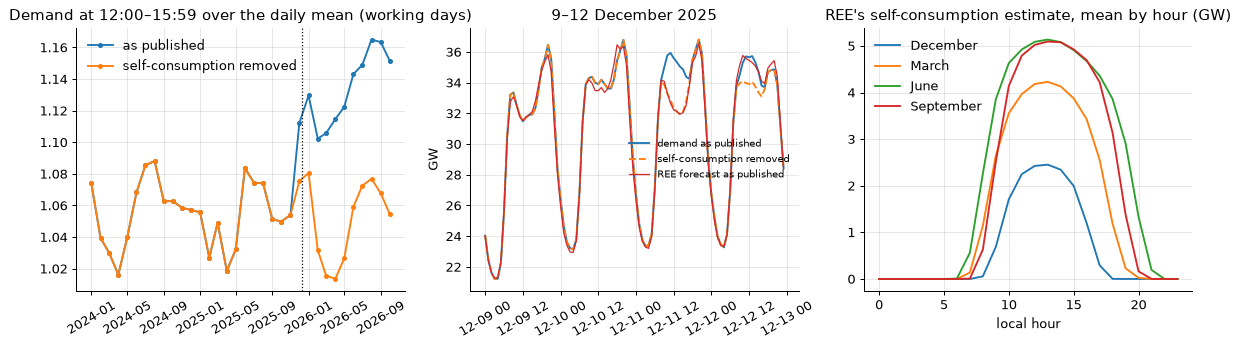

Self-consumption estimate, first hour: 2025-12-11 00:00:00+01:00
mean 1,617 MW, max 5,814 MW, share of published demand 5.5%
correlation of the midday estimate with solar radiation: 0.91
11 Dec 2025, the first day. REE's forecast was issued under the old definition: its mean error is -1,030 MW against published demand and -154 MW after the correction


In [4]:
work_all = ok[ok["day_type"] == "working"]
def midday_share(col):
    share = (work_all[col] / work_all.groupby("local_date")[col].transform("mean"))
    return share[work_all["local_hour"].between(12, 15)].groupby(work_all["local_date"].dt.to_period("M")).mean()
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for col, label in [("demand_published_mw", "as published"), ("demand_mw", "self-consumption removed")]:
    s = midday_share(col).loc["2024-01":]
    axes[0].plot(s.index.to_timestamp(), s.values, marker=".", label=label)
axes[0].axvline(pd.Timestamp("2025-12-11"), color="k", ls=":", lw=1)
axes[0].set(title="Demand at 12:00–15:59 over the daily mean (working days)")
axes[0].tick_params(axis="x", labelrotation=30)
axes[0].legend(frameon=False)
z = df[(df["local_date"] >= "2025-12-09") & (df["local_date"] <= "2025-12-12")]
zx = z.index.tz_convert("Europe/Madrid").tz_localize(None)
axes[1].plot(zx, z["demand_published_mw"] / 1000, label="demand as published")
axes[1].plot(zx, z["demand_mw"] / 1000, label="self-consumption removed", ls="--")
axes[1].plot(zx, z["ree_forecast_published_mw"] / 1000, label="REE forecast as published", color="C3", lw=1)
axes[1].set(title="9–12 December 2025", ylabel="GW")
axes[1].tick_params(axis="x", labelrotation=30)
axes[1].legend(frameon=False, fontsize=8)
post = df[df["post_definition_change"]]
prof = post.groupby([post["local_date"].dt.month, "local_hour"])["selfcons_mw"].mean().unstack(0) / 1000
for month in (12, 3, 6, 9):
    axes[2].plot(prof.index, prof[month], label=pd.Timestamp(2026, month, 1).strftime("%B"))
axes[2].set(title="REE's self-consumption estimate, mean by hour (GW)", xlabel="local hour")
axes[2].legend(frameon=False)
fig.savefig(FIG / "eda_definition_change.png", bbox_inches="tight")
plt.show()
print("Self-consumption estimate, first hour:", post.index[0].tz_convert("Europe/Madrid"))
print(f"mean {post['selfcons_mw'].mean():,.0f} MW, max {post['selfcons_mw'].max():,.0f} MW, "
      f"share of published demand {100 * post['selfcons_mw'].sum() / post['demand_published_mw'].sum():.1f}%")
mid = post[post["local_hour"].between(12, 15)].groupby("local_date")[["selfcons_mw", "rad_obs"]].mean()
print("correlation of the midday estimate with solar radiation:", round(mid["selfcons_mw"].corr(mid["rad_obs"]), 2))
d11 = df[df["local_date"] == "2025-12-11"]
print("11 Dec 2025, the first day. REE's forecast was issued under the old definition: its mean error is "
      f"{(d11['ree_forecast_published_mw'] - d11['demand_published_mw']).mean():,.0f} MW against published demand "
      f"and {(d11['ree_forecast_mw'] - d11['demand_mw']).mean():,.0f} MW after the correction")

## 3. The whole series and its trend

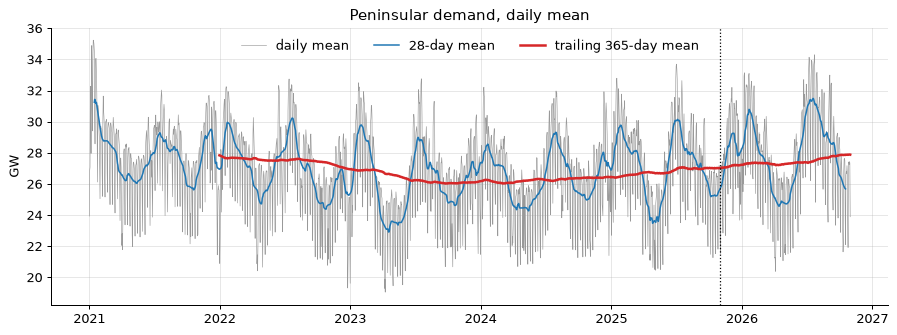

      mean_gw  peak_gw  min_gw  mean_temp    twh
year                                            
2021    27.84    41.83   17.45      16.35 243.86
2022    26.95    37.90   16.12      17.47 236.05
2023    26.17    38.83   16.19      17.30 229.28
2024    26.44    38.01   17.47      17.03 232.25
2025    27.24    39.79   17.63      17.36 237.31
2026    27.89    41.09   17.81      19.32 203.48
(2026 covers January to October only)


In [5]:
daily = ok.groupby("local_date").agg(gw=("gw", "mean"), temp=("temp_obs", "mean"),
                                     day_type=("day_type", "first"), hol=("holiday_intensity", "first"),
                                     bridge=("bridge_intensity", "first"), august=("august", "first"),
                                     christmas=("christmas", "first"), holy_week=("holy_week", "first"),
                                     n=("gw", "count"))
daily = daily[daily["n"] >= 23]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(daily.index, daily["gw"], lw=0.5, color="0.6", label="daily mean")
ax.plot(daily.index, daily["gw"].rolling(28, center=True).mean(), lw=1.2, color="C0", label="28-day mean")
ax.plot(daily.index, daily["gw"].rolling(365).mean(), lw=2, color="C3", label="trailing 365-day mean")
ax.axvline(TEST_START, color="k", ls=":", lw=1)
ax.set(ylabel="GW", title="Peninsular demand, daily mean")
ax.legend(ncol=3, frameon=False)
fig.savefig(FIG / "eda_series.png", bbox_inches="tight")
plt.show()
yearly = ok.groupby("year").agg(mean_gw=("gw", "mean"), peak_gw=("gw", "max"), min_gw=("gw", "min"),
                                mean_temp=("temp_obs", "mean"))
yearly["twh"] = ok.groupby("year")["gw"].sum() / 1000
print(yearly.to_string())
print("(2026 covers January to October only)")

## 4. Seasonality: daily, weekly and yearly patterns

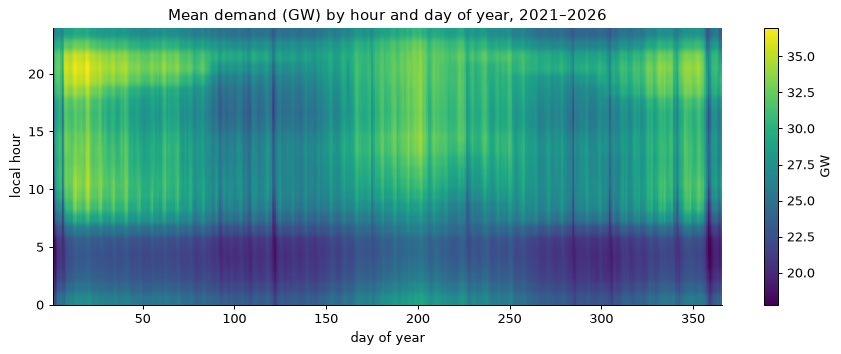

In [6]:
doy = ok["local_date"].dt.day_of_year
heat = ok.assign(doy=doy).pivot_table(index="local_hour", columns="doy", values="gw", aggfunc="mean")
fig, ax = plt.subplots(figsize=(12, 4))
im = ax.imshow(heat, aspect="auto", origin="lower", cmap="viridis", extent=[1, 366, 0, 24])
ax.set(xlabel="day of year", ylabel="local hour", title="Mean demand (GW) by hour and day of year, 2021–2026")
ax.grid(False)
fig.colorbar(im, ax=ax, label="GW")
fig.savefig(FIG / "eda_heatmap_hour_doy.png", bbox_inches="tight")
plt.show()

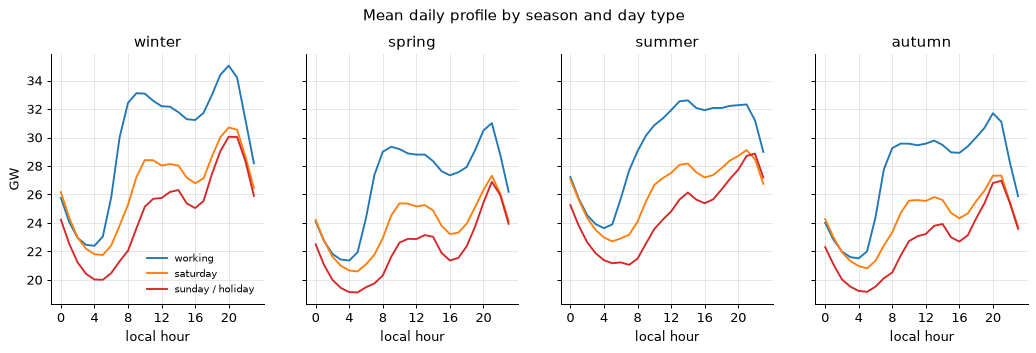

Mean demand by weekday (GW), Monday=0: {0: 27.6, 1: 28.41, 2: 28.45, 3: 28.34, 4: 28.01, 5: 25.12, 6: 23.51}
Saturday is -10.8% and Sunday -16.5% relative to the Monday–Friday mean


In [7]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6), sharey=True)
for ax, season in zip(axes, ["winter", "spring", "summer", "autumn"]):
    sub = ok[ok["season"] == season]
    for day_type, color in [("working", "C0"), ("saturday", "C1"), ("sunday_holiday", "C3")]:
        prof = sub[sub["day_type"] == day_type].groupby("local_hour")["gw"].mean()
        ax.plot(prof.index, prof.values, color=color, label=day_type.replace("_", " / "))
    ax.set(title=season, xlabel="local hour", xticks=range(0, 24, 4))
axes[0].set_ylabel("GW")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Mean daily profile by season and day type", y=1.02)
fig.savefig(FIG / "eda_profiles.png", bbox_inches="tight")
plt.show()
wk = ok.groupby(ok["weekday"])["gw"].mean()
print("Mean demand by weekday (GW), Monday=0:", wk.round(2).to_dict())
print(f"Saturday is {100 * (wk[5] / wk[:5].mean() - 1):.1f}% and Sunday {100 * (wk[6] / wk[:5].mean() - 1):.1f}% "
      "relative to the Monday–Friday mean")

## 5. Seasonality in the frequency domain

The profiles above suggest three cycles: daily, weekly and yearly. A Fourier spectrum checks this
directly. If the cycles are real, the power should sit in narrow peaks at periods of 24 h, 168 h and
8,766 h and at their harmonics (24/2, 24/3, …), with little in between.

**Set-up.** The four full years 2021–2024 (1,461 days), on a regular local-time grid of 24 values
per day, so the daily cycle does not shift by an hour at each clock change. The missing hour in
spring is interpolated and the repeated hour in autumn averaged. Four whole years put the yearly
and daily frequencies exactly on Fourier bins. The series is linearly detrended and tapered with a
Hann window to limit leakage.

In [8]:
span = df[(df["local_date"] >= "2021-01-01") & (df["local_date"] <= "2024-12-31")]
grid = span.pivot_table(index="local_date", columns="local_hour", values="demand_mw", aggfunc="mean")
grid = grid.interpolate(axis=1, limit_direction="both")
x = grid.to_numpy().ravel()
n = len(x)
t = np.arange(n)
x_detr = x - np.polyval(np.polyfit(t, x, 1), t)
window = np.hanning(n)
power = np.abs(np.fft.rfft(x_detr * window)) ** 2
power[0] = 0.0
share = power / power.sum()                 # share of the (windowed) variance in each bin
freq = np.fft.rfftfreq(n, d=1.0)            # cycles per hour
YEAR = n / 4                                # 8,766 hours
print(f"{n:,} hourly values = {n // 24:,} days; frequency resolution = one cycle per {n:,} h")

def label_period(period_h):
    """Name a period if it is a harmonic of the day, the week or the year, or a yearly
    side-peak of a daily harmonic (the daily cycle changing through the year). Tolerance 1.5 bins."""
    f = 1 / period_h
    tol = 1.5 / n
    for base, name, kmax in [(24, "day", 12), (168, "week", 24), (YEAR, "year", 20)]:
        k = round(f * base)
        if 1 <= k <= kmax and abs(f - k / base) <= tol:
            return name if k == 1 else f"{name}/{k}"
    kd = round(f * 24)
    j = round((f - kd / 24) * YEAR)
    if kd >= 1 and 1 <= abs(j) <= 4 and abs(f - kd / 24 - j / YEAR) <= tol:
        return f"{'day' if kd == 1 else f'day/{kd}'} {'+' if j > 0 else '−'} {abs(j)}/year"
    return "trend (lowest bin)" if round(f * n) == 1 else "—"

# Strongest peaks: local maxima of the spectrum, strongest first
is_peak = (share[1:-1] > share[:-2]) & (share[1:-1] > share[2:])
peak_bins = np.where(is_peak)[0] + 1
top = peak_bins[np.argsort(share[peak_bins])[::-1][:25]]
peaks = pd.DataFrame({"period_h": 1 / freq[top], "share_%": 100 * share[top]})
peaks["period_days"] = peaks["period_h"] / 24
peaks["matches"] = peaks["period_h"].map(label_period)
print("\nThe 25 strongest spectral peaks:")
print(peaks[["period_h", "period_days", "share_%", "matches"]].round(3).to_string(index=False))
print(f"\n{(peaks['matches'] != '—').sum()} of 25 are explained by the day, the week, the year or the trend")
print("(the weekly peaks sit at 167.8 h and not 168 h because four years are not a whole number of weeks)")

35,064 hourly values = 1,461 days; frequency resolution = one cycle per 35,064 h

The 25 strongest spectral peaks:
 period_h  period_days  share_%            matches
    24.00         1.00    21.53                day
   167.77         6.99     8.42               week
 4,383.00       182.62     7.69             year/2
    12.00         0.50     7.48              day/2
    84.09         3.50     2.12             week/2
    12.02         0.50     0.66     day/2 − 1/year
 1,753.20        73.05     0.64             year/5
 2,922.00       121.75     0.63             year/3
35,064.00     1,461.00     0.62 trend (lowest bin)
    28.01         1.17     0.61             week/6
 1,095.75        45.66     0.60             year/8
     6.00         0.25     0.41              day/4
    33.59         1.40     0.40             week/5
    56.01         2.33     0.34             week/3
 1,461.00        60.88     0.34             year/6
    24.13         1.01     0.29       day − 2/year
    11.98         

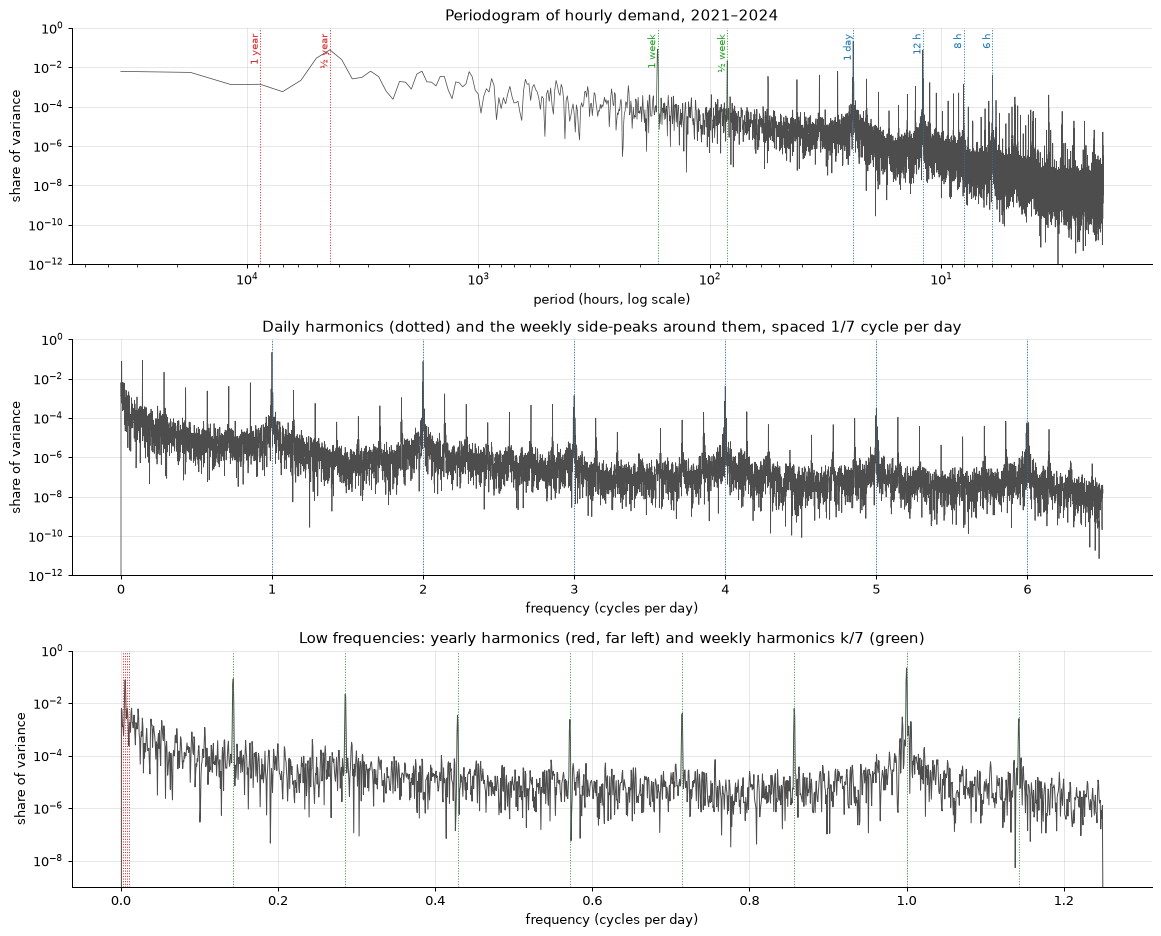

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(13, 10.5))
ax = axes[0]
ax.loglog(1 / freq[1:], share[1:], lw=0.6, color="0.3")
for period, name, color in [(YEAR, "1 year", "C3"), (YEAR / 2, "½ year", "C3"), (168, "1 week", "C2"),
                            (84, "½ week", "C2"), (24, "1 day", "C0"), (12, "12 h", "C0"),
                            (8, "8 h", "C0"), (6, "6 h", "C0")]:
    ax.axvline(period, color=color, lw=0.8, ls=":")
    ax.text(period, 0.5, name, color=color, rotation=90, va="top", ha="right", fontsize=8)
ax.set(xlabel="period (hours, log scale)", ylabel="share of variance", ylim=(1e-12, 1),
       title="Periodogram of hourly demand, 2021–2024")
ax.invert_xaxis()

cpd = freq * 24                              # cycles per day
ax = axes[1]
sel = cpd <= 6.5
ax.semilogy(cpd[sel], share[sel], lw=0.6, color="0.3")
for k in range(1, 7):
    ax.axvline(k, color="C0", lw=0.8, ls=":")
ax.set(xlabel="frequency (cycles per day)", ylabel="share of variance", ylim=(1e-12, 1),
       title="Daily harmonics (dotted) and the weekly side-peaks around them, spaced 1/7 cycle per day")

ax = axes[2]
sel = cpd <= 1.25
ax.semilogy(cpd[sel], share[sel], lw=0.8, color="0.3")
for k in range(1, 9):
    ax.axvline(k / 7, color="C2", lw=0.8, ls=":")
for k in range(1, 5):
    ax.axvline(k * 24 / YEAR, color="C3", lw=0.8, ls=":")
ax.set(xlabel="frequency (cycles per day)", ylabel="share of variance", ylim=(1e-9, 1),
       title="Low frequencies: yearly harmonics (red, far left) and weekly harmonics k/7 (green)")
fig.tight_layout()
fig.savefig(FIG / "eda_spectrum.png", bbox_inches="tight")
plt.show()

### How many harmonics does each cycle need?

A least-squares fit of sines and cosines at the expected frequencies gives the amplitude of each
harmonic in MW, and the share of variance each cycle explains. This is the additive Fourier model
of DESIGN §6, with nothing else in it (no temperature, no holidays, no interaction between cycles).

In [10]:
K = {"year": (YEAR, 8), "week": (168, 14), "day": (24, 10)}
columns, names = [np.ones(n)], [("const", 0)]
for cycle, (period, kmax) in K.items():
    for k in range(1, kmax + 1):
        if cycle == "week" and k % 7 == 0:
            continue                         # 168/7 = 24 h: already a daily harmonic
        columns += [np.cos(2 * np.pi * k * t / period), np.sin(2 * np.pi * k * t / period)]
        names += [(cycle, k), (cycle, k)]
X = np.column_stack(columns)
coef, *_ = np.linalg.lstsq(X, x_detr, rcond=None)
total_var = x_detr.var()
rows = []
for cycle, (period, kmax) in K.items():
    for k in range(1, kmax + 1):
        idx = [i for i, nm in enumerate(names) if nm == (cycle, k)]
        if not idx:
            continue
        amp = np.hypot(*coef[idx])
        rows.append({"cycle": cycle, "k": k, "period_h": period / k, "amplitude_mw": amp,
                     "variance_%": 100 * (amp**2 / 2) / total_var})
harm = pd.DataFrame(rows)
harm["cumulative_%"] = harm.groupby("cycle")["variance_%"].cumsum()
for cycle in K:
    print(f"\n{cycle} harmonics")
    print(harm[harm["cycle"] == cycle].drop(columns="cycle").round(2).to_string(index=False))
fitted = X @ coef
r2 = 1 - ((x_detr - fitted) ** 2).sum() / (x_detr**2).sum()
by_cycle = harm.groupby("cycle")["variance_%"].sum().reindex(["year", "week", "day"])
print("\nShare of variance by cycle (%):", by_cycle.round(1).to_dict())
print(f"All harmonics together: R² = {r2:.3f}; residual sd = {np.std(x_detr - fitted):,.0f} MW "
      f"(series sd = {x_detr.std():,.0f} MW)")

# Power that sits exactly on weekly side-peaks around the daily harmonics (day profile differs by weekday)
side = 0.0
for kd in range(1, 9):
    for j in range(1, 4):
        for sign in (-1, 1):
            b = int(round((kd / 24 + sign * j / 168) * n))
            side += share[b - 2 : b + 3].sum()
print(f"Weekly side-peaks around daily harmonics 1–8 (±1, ±2, ±3 sevenths of a cycle per day): "
      f"{100 * side:.2f}% of the variance")


year harmonics
 k  period_h  amplitude_mw  variance_%  cumulative_%
 1  8,766.00        441.81        0.55          0.55
 2  4,383.00      1,877.79        9.97         10.52
 3  2,922.00        397.36        0.45         10.96
 4  2,191.50        242.89        0.17         11.13
 5  1,753.20        389.73        0.43         11.56
 6  1,461.00        402.67        0.46         12.02
 7  1,252.29        257.92        0.19         12.21
 8  1,095.75        583.99        0.96         13.17

week harmonics
 k  period_h  amplitude_mw  variance_%  cumulative_%
 1    168.00      2,223.64       13.98         13.98
 2     84.00      1,237.60        4.33         18.31
 3     56.00        438.53        0.54         18.85
 4     42.00        361.71        0.37         19.22
 5     33.60        535.81        0.81         20.03
 6     28.00        594.14        1.00         21.03
 8     21.00        390.14        0.43         21.46
 9     18.67        204.86        0.12         21.58
10     16.80  

**Reading the result.** The side-peaks around each daily harmonic are the signature of an
*interaction*: the shape of the day is not the same on every weekday, so a purely additive
"daily + weekly" Fourier model cannot represent it. This is why the design lets the daily
profile depend on the day type.

## 6. The midday dip: a fingerprint of rooftop solar

Self-consumption solar does not appear as generation: it lowers the *measured* demand around
midday. If it is growing, the working-day profile should sag more each year between about 11:00
and 16:00, most visibly in spring, when the sun is strong and air conditioning is off.

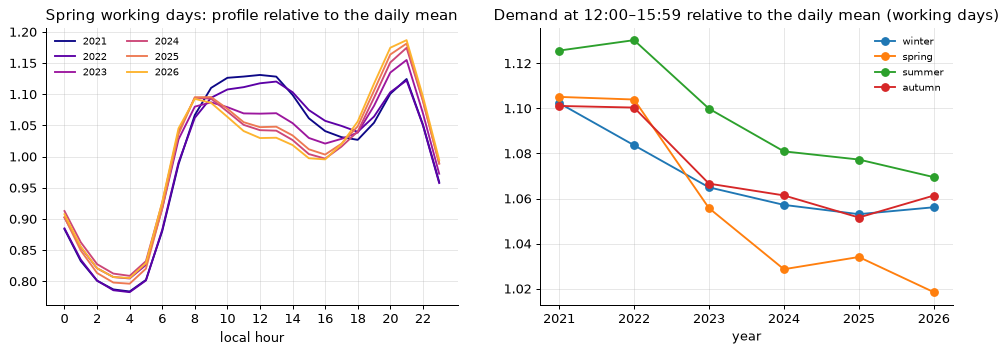

season  winter  spring  summer  autumn
year                                  
2021      1.10    1.10    1.13    1.10
2022      1.08    1.10    1.13    1.10
2023      1.06    1.06    1.10    1.07
2024      1.06    1.03    1.08    1.06
2025      1.05    1.03    1.08    1.05
2026      1.06    1.02    1.07    1.06


In [11]:
spring = ok[(ok["season"] == "spring") & (ok["day_type"] == "working")]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
cmap = plt.get_cmap("plasma")
years = sorted(spring["year"].unique())
for i, year in enumerate(years):
    prof = spring[spring["year"] == year].groupby("local_hour")["gw"].mean()
    axes[0].plot(prof.index, prof / prof.mean(), color=cmap(i / len(years)), label=str(year))
axes[0].set(title="Spring working days: profile relative to the daily mean", xlabel="local hour",
            xticks=range(0, 24, 2))
axes[0].legend(frameon=False, ncol=2, fontsize=8)
work = ok[ok["day_type"] == "working"]
day_mean = work.groupby("local_date")["gw"].transform("mean")
ratio = (work["gw"] / day_mean)[work["local_hour"].between(12, 15)]
dip = ratio.groupby([work["year"], work["season"]]).mean().unstack()[["winter", "spring", "summer", "autumn"]]
dip.plot(ax=axes[1], marker="o")
axes[1].set(title="Demand at 12:00–15:59 relative to the daily mean (working days)", xlabel="year")
axes[1].legend(frameon=False, fontsize=8)
fig.savefig(FIG / "eda_midday_dip.png", bbox_inches="tight")
plt.show()
print(dip.round(3).to_string())

## 7. Demand and temperature

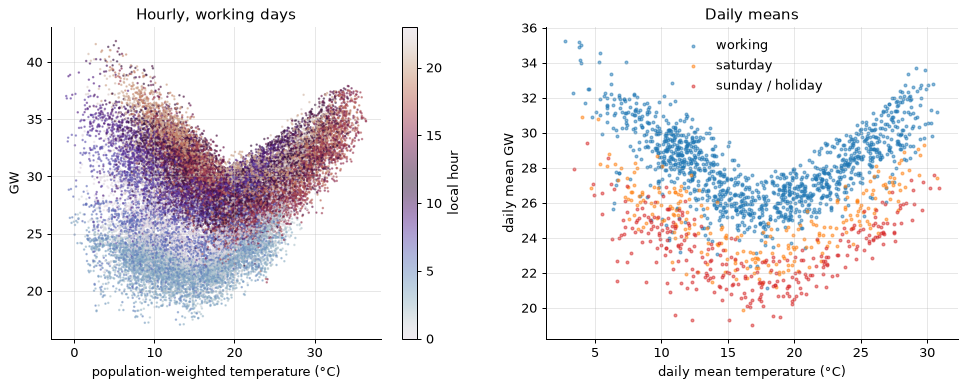

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
w = dev[dev["day_type"] == "working"]
sc = axes[0].scatter(w["temp_obs"], w["gw"], c=w["local_hour"], s=1, cmap="twilight", alpha=0.5, rasterized=True)
fig.colorbar(sc, ax=axes[0], label="local hour")
axes[0].set(xlabel="population-weighted temperature (°C)", ylabel="GW", title="Hourly, working days")
dd = daily[(daily.index < TEST_START)]
for day_type, color in [("working", "C0"), ("saturday", "C1"), ("sunday_holiday", "C3")]:
    s = dd[dd["day_type"] == day_type]
    axes[1].scatter(s["temp"], s["gw"], s=5, color=color, alpha=0.5, label=day_type.replace("_", " / "))
axes[1].set(xlabel="daily mean temperature (°C)", ylabel="daily mean GW", title="Daily means")
axes[1].legend(frameon=False)
fig.savefig(FIG / "eda_temperature_scatter.png", bbox_inches="tight")
plt.show()

### A first estimate of the heating and cooling thresholds

A piecewise-linear ("hinge") fit on working-day daily means, excluding August, Christmas, Holy Week
and bridge days: $y = a + \beta_H \max(T_H - T, 0) + \beta_C \max(T - T_C, 0) + \text{year effect}$.
The thresholds are found by grid search and the rest by least squares. This is only a rough guide
for priors in the Bayesian model (DESIGN §7.3), not a result.

In [13]:
def hinge_fit(frame, temp_col="temp"):
    """Grid search over (T_H, T_C); returns the best fit as a dict."""
    y = frame["gw"].to_numpy()
    t = frame[temp_col].to_numpy()
    years_dummies = pd.get_dummies(frame.index.year, dtype=float).to_numpy()
    best = None
    for th in np.arange(10, 20.01, 0.25):
        for tc in np.arange(max(th, 16), 26.01, 0.25):
            X = np.column_stack([np.maximum(th - t, 0), np.maximum(t - tc, 0), years_dummies])
            coef, *_ = np.linalg.lstsq(X, y, rcond=None)
            sse = ((y - X @ coef) ** 2).sum()
            if best is None or sse < best["sse"]:
                best = {"sse": sse, "th": th, "tc": tc, "beta_h": coef[0], "beta_c": coef[1],
                        "year_levels": coef[2:], "resid": y - X @ coef}
    best["r2"] = 1 - best["sse"] / ((y - y.mean()) ** 2).sum()
    best["rmse"] = np.sqrt(best["sse"] / len(y))
    return best

special = dd["august"] | dd["christmas"] | dd["holy_week"] | (dd["bridge"] > 0.3) | (dd["hol"] > 0.1)
base = dd[(dd["day_type"] == "working") & ~special].copy()
fit = hinge_fit(base)
print(f"T_H = {fit['th']:.2f} °C   T_C = {fit['tc']:.2f} °C")
print(f"heating sensitivity = {1000 * fit['beta_h']:.0f} MW per °C below T_H (daily mean)")
print(f"cooling sensitivity = {1000 * fit['beta_c']:.0f} MW per °C above T_C (daily mean)")
print(f"R² = {fit['r2']:.3f}   RMSE = {1000 * fit['rmse']:.0f} MW   n = {len(base)} days")
print("comfort-band level by year (GW):", dict(zip(sorted(set(base.index.year)), fit["year_levels"].round(2))))

T_H = 16.00 °C   T_C = 20.25 °C
heating sensitivity = 590 MW per °C below T_H (daily mean)
cooling sensitivity = 670 MW per °C above T_C (daily mean)
R² = 0.840   RMSE = 837 MW   n = 1020 days
comfort-band level by year (GW): {2021: np.float64(27.02), 2022: np.float64(26.07), 2023: np.float64(25.46), 2024: np.float64(25.83), 2025: np.float64(26.13)}


### Thermal inertia

Buildings respond to the temperature of the last few days, not only today's. Replace the daily
temperature by an exponential moving average, $T^*_d = \lambda T^*_{d-1} + (1-\lambda) T_d$, and see
which $\lambda$ fits best.

        rmse_mw   r2   T_H   T_C  beta_h_mw  beta_c_mw
lambda                                                
0.00     837.06 0.84 16.00 20.25     590.00     670.03
0.20     790.09 0.86 16.00 20.25     599.68     683.17
0.40     742.84 0.87 16.00 20.00     616.61     675.23
0.50     721.82 0.88 15.75 20.25     633.68     699.52
0.60     708.07 0.89 15.75 20.25     639.74     709.37
0.70     710.49 0.88 15.50 20.00     673.41     686.66
0.80     755.66 0.87 15.25 20.50     689.51     746.92
0.90     973.88 0.78 15.25 20.25     685.10     723.20


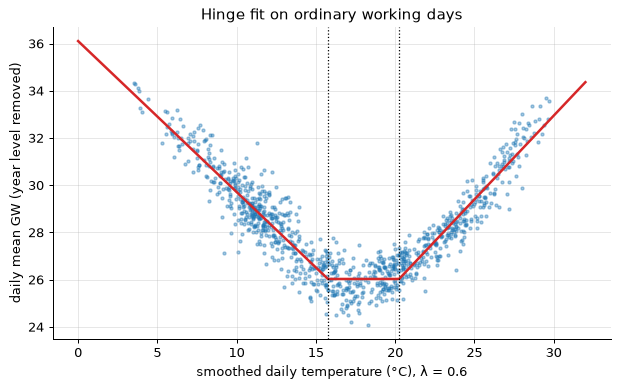

In [14]:
all_days_temp = df.groupby("local_date")["temp_obs"].mean()
rows = []
for lam in [0.0, 0.2, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    smooth = all_days_temp.ewm(alpha=1 - lam, adjust=False).mean()
    f = hinge_fit(base.assign(ts=smooth.reindex(base.index)), "ts")
    rows.append({"lambda": lam, "rmse_mw": 1000 * f["rmse"], "r2": f["r2"], "T_H": f["th"], "T_C": f["tc"],
                 "beta_h_mw": 1000 * f["beta_h"], "beta_c_mw": 1000 * f["beta_c"]})
inertia = pd.DataFrame(rows).set_index("lambda")
print(inertia.round(3).to_string())
best_lam = inertia["rmse_mw"].idxmin()
smooth = all_days_temp.ewm(alpha=1 - best_lam, adjust=False).mean()
fit_s = hinge_fit(base.assign(ts=smooth.reindex(base.index)), "ts")

fig, ax = plt.subplots(figsize=(8, 4.5))
level = pd.Series(fit_s["year_levels"], index=sorted(set(base.index.year)))
adj = base["gw"] - level.reindex(base.index.year).to_numpy() + level.mean()
ax.scatter(smooth.reindex(base.index), adj, s=6, alpha=0.4, color="C0")
grid = np.linspace(0, 32, 200)
ax.plot(grid, level.mean() + fit_s["beta_h"] * np.maximum(fit_s["th"] - grid, 0)
        + fit_s["beta_c"] * np.maximum(grid - fit_s["tc"], 0), color="C3", lw=2)
for x in (fit_s["th"], fit_s["tc"]):
    ax.axvline(x, color="k", ls=":", lw=1)
ax.set(xlabel=f"smoothed daily temperature (°C), λ = {best_lam}", ylabel="daily mean GW (year level removed)",
       title="Hinge fit on ordinary working days")
fig.savefig(FIG / "eda_hinge.png", bbox_inches="tight")
plt.show()

### Is the level drifting once temperature is accounted for?

Comfort-band level of ordinary working days by year, after the temperature terms (GW):
2021   26.92
2022   25.96
2023   25.42
2024   25.81
2025   26.03


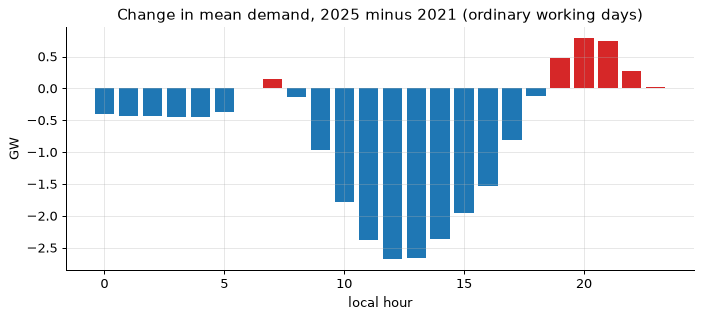

0    -0.40
1    -0.43
2    -0.44
3    -0.45
4    -0.45
5    -0.38
6     0.01
7     0.15
8    -0.13
9    -0.96
10   -1.77
11   -2.38
12   -2.67
13   -2.65
14   -2.37
15   -1.95
16   -1.53
17   -0.81
18   -0.11
19    0.48
20    0.79
21    0.74
22    0.27
23    0.02


In [15]:
print("Comfort-band level of ordinary working days by year, after the temperature terms (GW):")
print(level.round(2).to_string())
by_hour = []
for hour in range(24):
    sub = dev[(dev["local_hour"] == hour) & dev["local_date"].isin(base.index)]
    by_hour.append(sub.groupby("year")["gw"].mean().rename(hour))
by_hour = pd.concat(by_hour, axis=1).T
change = (by_hour[2025] - by_hour[2021])
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(change.index, change.values, color=np.where(change > 0, "C3", "C0"))
ax.set(xlabel="local hour", ylabel="GW", title="Change in mean demand, 2025 minus 2021 (ordinary working days)")
fig.savefig(FIG / "eda_change_by_hour.png", bbox_inches="tight")
plt.show()
print(change.round(2).to_string())

## 8. Holidays, bridge days and special periods

Each day is compared with a reference: the median of the same weekday in the four weeks before
and after, using only ordinary days. The ratio is the day's daily-mean demand over that reference.

                                         days  median ratio  p10  p90
ordinary working day                   956.00          1.00 0.96 1.06
national holiday (weekday)              35.00          0.82 0.73 0.89
regional holiday, intensity 0.3–0.99    17.00          0.87 0.83 0.97
regional holiday, intensity 0.05–0.3    36.00          0.98 0.88 1.01
regional holiday, intensity < 0.05      34.00          1.02 0.96 1.08
bridge day (intensity ≥ 0.5)             9.00          0.91 0.88 0.99
August (non-holiday weekday)           106.00          0.98 0.90 1.08
Christmas period (non-holiday weekday)  31.00          0.90 0.82 0.96
Holy Week (non-holiday weekday)         15.00          0.97 0.94 1.01


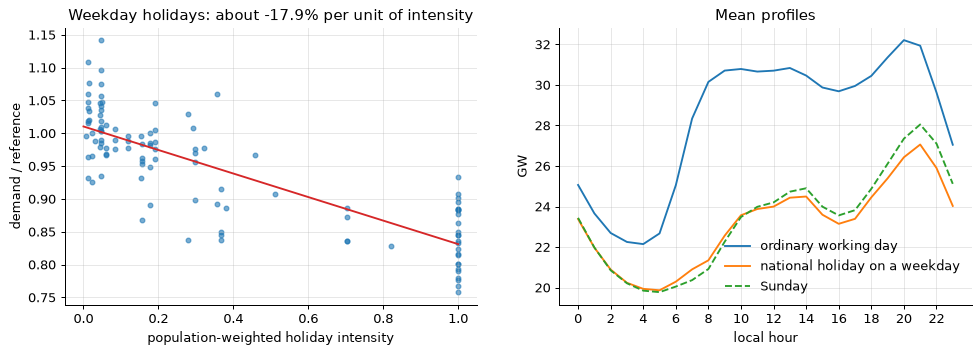

In [16]:
full = daily[daily.index < TEST_START].copy()
ordinary = (full["hol"] == 0) & (full["bridge"] == 0) & ~full["christmas"] & ~full["august"] & ~full["holy_week"]
ref = pd.Series(np.nan, index=full.index)
ord_series = full["gw"].where(ordinary)
shifted = pd.concat([ord_series.shift(7 * k, freq="D") for k in (-4, -3, -2, -1, 1, 2, 3, 4)], axis=1, sort=True)
ref = shifted.reindex(full.index).median(axis=1)
full["ratio"] = full["gw"] / ref
wd = full[full.index.day_of_week < 5]
groups = {
    "ordinary working day": wd[ordinary.reindex(wd.index)],
    "national holiday (weekday)": wd[wd["hol"] == 1],
    "regional holiday, intensity 0.3–0.99": wd[(wd["hol"] >= 0.3) & (wd["hol"] < 1)],
    "regional holiday, intensity 0.05–0.3": wd[(wd["hol"] >= 0.05) & (wd["hol"] < 0.3)],
    "regional holiday, intensity < 0.05": wd[(wd["hol"] > 0) & (wd["hol"] < 0.05)],
    "bridge day (intensity ≥ 0.5)": wd[wd["bridge"] >= 0.5],
    "August (non-holiday weekday)": wd[wd["august"] & (wd["hol"] == 0)],
    "Christmas period (non-holiday weekday)": wd[wd["christmas"] & (wd["hol"] == 0)],
    "Holy Week (non-holiday weekday)": wd[wd["holy_week"] & (wd["hol"] == 0)],
}
tab = pd.DataFrame({k: {"days": len(v), "median ratio": v["ratio"].median(), "p10": v["ratio"].quantile(0.1),
                        "p90": v["ratio"].quantile(0.9)} for k, v in groups.items()}).T
print(tab.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
h = wd[(wd["hol"] > 0) & ~wd["christmas"]]
axes[0].scatter(h["hol"], h["ratio"], s=14, alpha=0.6)
slope = np.polyfit(h["hol"], h["ratio"] - 1, 1)
axes[0].plot([0, 1], [1 + slope[1], 1 + slope[0] + slope[1]], color="C3")
axes[0].set(xlabel="population-weighted holiday intensity", ylabel="demand / reference",
            title=f"Weekday holidays: about {100 * slope[0]:.1f}% per unit of intensity")
nat = dev[(dev["holiday_national"]) & (dev["weekday"] < 5) & ~dev["christmas"]].groupby("local_hour")["gw"].mean()
ordw = dev[dev["local_date"].isin(full.index[ordinary]) & (dev["weekday"] < 5)].groupby("local_hour")["gw"].mean()
sun = dev[(dev["weekday"] == 6) & (dev["holiday_intensity"] == 0)].groupby("local_hour")["gw"].mean()
axes[1].plot(ordw, label="ordinary working day")
axes[1].plot(nat, label="national holiday on a weekday")
axes[1].plot(sun, label="Sunday", ls="--")
axes[1].set(xlabel="local hour", ylabel="GW", title="Mean profiles", xticks=range(0, 24, 2))
axes[1].legend(frameon=False)
fig.savefig(FIG / "eda_holidays.png", bbox_inches="tight")
plt.show()

## 9. Autocorrelation

Left: raw hourly demand. Right: what remains after removing the mean for each
(month, day type, hour) and a per-year level; a crude stand-in for "seasonality removed".

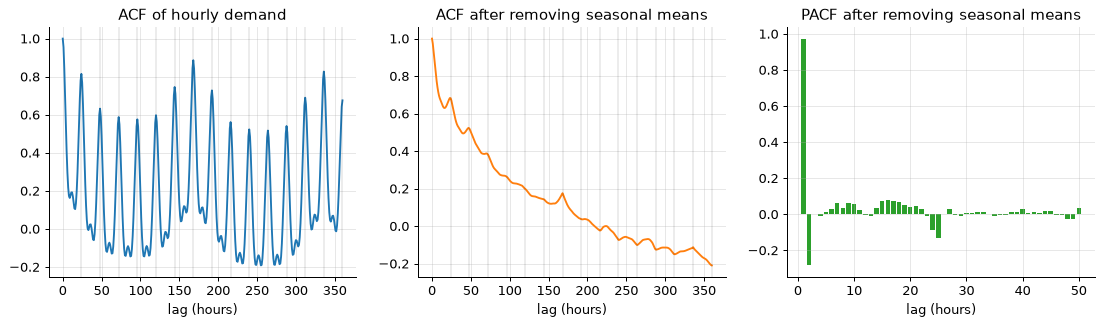

residual sd: 1324 MW
  residual ACF at lag   1 h: 0.974
  residual ACF at lag   2 h: 0.934
  residual ACF at lag  14 h: 0.640
  residual ACF at lag  24 h: 0.682
  residual ACF at lag  38 h: 0.501
  residual ACF at lag  48 h: 0.521
  residual ACF at lag 168 h: 0.176
  PACF lags 1–3: [ 0.974 -0.283  0.003]  lag 24: -0.089  lag 25: -0.13


In [17]:
def acf(x, nlags):
    x = np.asarray(x, dtype=float)
    x = x - np.nanmean(x)
    x = np.nan_to_num(x)
    denom = (x ** 2).sum()
    return np.array([1.0] + [(x[k:] * x[:-k]).sum() / denom for k in range(1, nlags + 1)])

def pacf(r, nlags):
    """Partial autocorrelations from autocorrelations r[0..nlags] (Durbin–Levinson)."""
    phi = np.zeros((nlags + 1, nlags + 1))
    out = [1.0]
    for k in range(1, nlags + 1):
        num = r[k] - (phi[k - 1, 1:k] * r[1:k][::-1]).sum()
        den = 1 - (phi[k - 1, 1:k] * r[1:k]).sum()
        phi[k, k] = num / den
        phi[k, 1:k] = phi[k - 1, 1:k] - phi[k, k] * phi[k - 1, 1:k][::-1]
        out.append(phi[k, k])
    return np.array(out)

devx = df[df["local_date"] < TEST_START].copy()
devx.loc[devx["is_masked"], "demand_mw"] = np.nan
cell_mean = devx.groupby(["year", "month", "day_type", "local_hour"])["demand_mw"].transform("mean")
devx["resid"] = devx["demand_mw"] - cell_mean
r_raw, r_res = acf(devx["demand_mw"], 24 * 15), acf(devx["resid"], 24 * 15)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
axes[0].plot(r_raw)
axes[0].set(title="ACF of hourly demand", xlabel="lag (hours)")
axes[1].plot(r_res, color="C1")
axes[1].set(title="ACF after removing seasonal means", xlabel="lag (hours)")
p = pacf(r_res, 50)
axes[2].bar(range(1, 51), p[1:], color="C2")
axes[2].set(title="PACF after removing seasonal means", xlabel="lag (hours)")
for ax in axes[:2]:
    for k in range(1, 16):
        ax.axvline(24 * k, color="k", lw=0.3, alpha=0.4)
fig.savefig(FIG / "eda_acf.png", bbox_inches="tight")
plt.show()
print("residual sd:", round(devx["resid"].std()), "MW")
for lag in (1, 2, 14, 24, 38, 48, 168):
    print(f"  residual ACF at lag {lag:>3} h: {r_res[lag]:.3f}")
print("  PACF lags 1–3:", p[1:4].round(3), " lag 24:", round(p[24], 3), " lag 25:", round(p[25], 3))

Lags 14 to 38 hours matter most: with the forecast issued at 10:00, they are the distance between
the last observed hour and the target hours of the next day.

## 10. Special periods

### The 28 April 2025 blackout

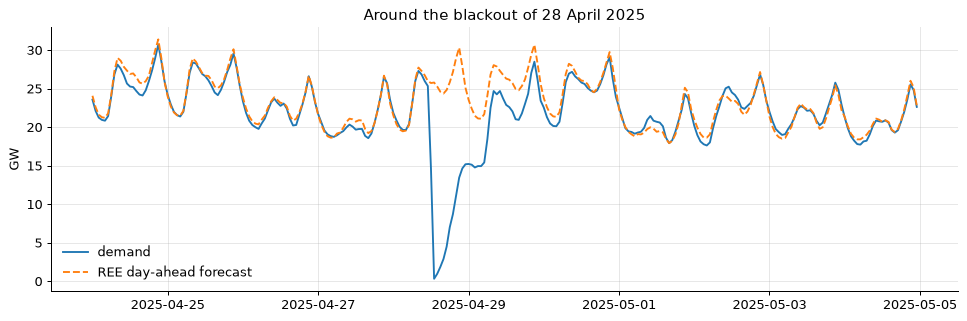

            demand_gw  ree_gw  min_gw  holiday  gap_pct
local_date                                             
2025-04-26      22.25   22.60   19.78     0.00    -1.54
2025-04-27      20.63   20.91   18.58     0.00    -1.33
2025-04-28      15.51   24.74    0.33     0.00   -37.30
2025-04-29      21.36   25.56   14.77     0.00   -16.44
2025-04-30      24.64   25.40   20.12     0.00    -2.96
2025-05-01      20.51   20.20   17.92     1.00     1.53
2025-05-02      22.40   22.46   17.63     0.16    -0.30


In [18]:
win = df[(df["local_date"] >= "2025-04-24") & (df["local_date"] <= "2025-05-04")]
x = win.index.tz_convert("Europe/Madrid").tz_localize(None)
fig, ax = plt.subplots(figsize=(13, 3.8))
ax.plot(x, win["gw"], label="demand")
ax.plot(x, win["ree_forecast_mw"] / 1000, label="REE day-ahead forecast", ls="--")
ax.set(ylabel="GW", title="Around the blackout of 28 April 2025")
ax.legend(frameon=False)
fig.savefig(FIG / "eda_blackout.png", bbox_inches="tight")
plt.show()
b = df[(df["local_date"] >= "2025-04-26") & (df["local_date"] <= "2025-05-02")]
bd = b.groupby("local_date").agg(demand_gw=("gw", "mean"), ree_gw=("ree_forecast_mw", lambda s: s.mean() / 1000),
                                 min_gw=("gw", "min"), holiday=("holiday_intensity", "first"))
bd["gap_pct"] = 100 * (bd["demand_gw"] / bd["ree_gw"] - 1)
print(bd.round(2).to_string())

### Other unusual days

Days whose demand is furthest from REE's own day-ahead forecast are a convenient list of "events".

In [19]:
both = df.dropna(subset=["demand_mw", "ree_forecast_mw"]).copy()
both["err"] = both["ree_forecast_mw"] - both["demand_mw"]
both["ape"] = both["err"].abs() / both["demand_mw"]
worst = both.groupby("local_date").agg(mape=("ape", "mean"), bias_mw=("err", "mean"), hol=("holiday_intensity", "first"),
                                       bridge=("bridge_intensity", "first"), temp=("temp_obs", "mean"))
worst["weekday"] = worst.index.day_name().str[:3]
print(worst.nlargest(15, "mape").assign(mape=lambda t: 100 * t["mape"]).round(2).to_string())

             mape   bias_mw  hol  bridge  temp weekday
local_date                                            
2025-04-28 569.71  9,229.74 0.00    0.00 16.88     Mon
2025-04-29  22.29  4,201.08 0.00    0.00 16.98     Tue
2023-08-27   8.13  1,851.55 0.00    0.00 22.44     Sun
2026-06-11   7.34  1,805.58 0.00    0.00 22.68     Thu
2022-12-26   6.84  1,471.37 0.77    0.00 11.89     Mon
2024-12-09   6.82 -2,062.96 0.36    0.00  8.45     Mon
2025-09-22   6.33  1,615.98 0.00    0.00 18.75     Mon
2025-03-30   6.28  1,128.10 0.00    0.00 12.28     Sun
2025-03-29   5.78  1,272.38 0.00    0.00 12.97     Sat
2025-03-28   5.66  1,531.31 0.00    0.00 12.49     Fri
2024-03-25   5.25 -1,477.87 0.00    0.00 13.02     Mon
2023-08-28   5.08  1,305.00 0.00    0.00 22.73     Mon
2025-04-01   5.05  1,307.54 0.00    0.00 14.23     Tue
2021-01-05   5.03 -1,658.43 0.00    0.00  3.38     Tue
2026-04-03   5.01 -1,043.39 1.00    0.00 14.04     Fri


## 11. REE's day-ahead forecast: how good is the professional benchmark?

Indicator 1775, published at about 10:50 on the previous day. Errors are forecast minus actual.
Blackout days are excluded.

In [20]:
bk = both[~both["is_masked"]].copy()
def scores(g):
    return pd.Series({"hours": len(g), "MAE_MW": g["err"].abs().mean(), "RMSE_MW": np.sqrt((g["err"] ** 2).mean()),
                      "MAPE_%": 100 * g["ape"].mean(), "bias_MW": g["err"].mean()})
bk["split"] = np.select([bk["local_date"] < splits["validation"]["start"], bk["local_date"] < TEST_START],
                        ["train", "validation"], "test")
print(pd.concat([bk.groupby("split").apply(scores, include_groups=False).loc[["train", "validation", "test"]],
                 scores(bk).rename("all").to_frame().T]).round(2).to_string())
print()
print(bk.groupby("year").apply(scores, include_groups=False).round(2).to_string())

# Reference: seasonal naive forecasts available at 10:00 on the previous day
y = df["demand_mw"].where(~df["is_masked"])
naive = pd.DataFrame({"y": y, "week": y.shift(168), "two_days": y.shift(48)}).dropna()
print("\nFor scale, naive forecasts over the same period:")
for col, name in [("week", "same hour one week earlier"), ("two_days", "same hour two days earlier")]:
    print(f"  {name}: MAPE {100 * ((naive[col] - naive['y']).abs() / naive['y']).mean():.2f}%")

               hours  MAE_MW  RMSE_MW  MAPE_%  bias_MW
train      33,600.00  371.52   508.33    1.37     2.18
validation  8,712.00  454.87   640.76    1.67    10.61
test        8,760.00  430.05   594.12    1.54   -10.81
all        51,072.00  395.78   548.25    1.45     1.39

        hours  MAE_MW  RMSE_MW  MAPE_%  bias_MW
year                                           
2021 8,760.00  344.27   458.21    1.23    29.83
2022 8,760.00  347.31   462.98    1.28    -2.87
2023 8,760.00  376.35   517.99    1.42   -16.94
2024 8,784.00  422.06   592.97    1.58   -11.73
2025 8,712.00  457.92   640.06    1.67    -0.54
2026 7,296.00  433.29   599.96    1.56    12.48

For scale, naive forecasts over the same period:
  same hour one week earlier: MAPE 4.95%
  same hour two days earlier: MAPE 10.53%


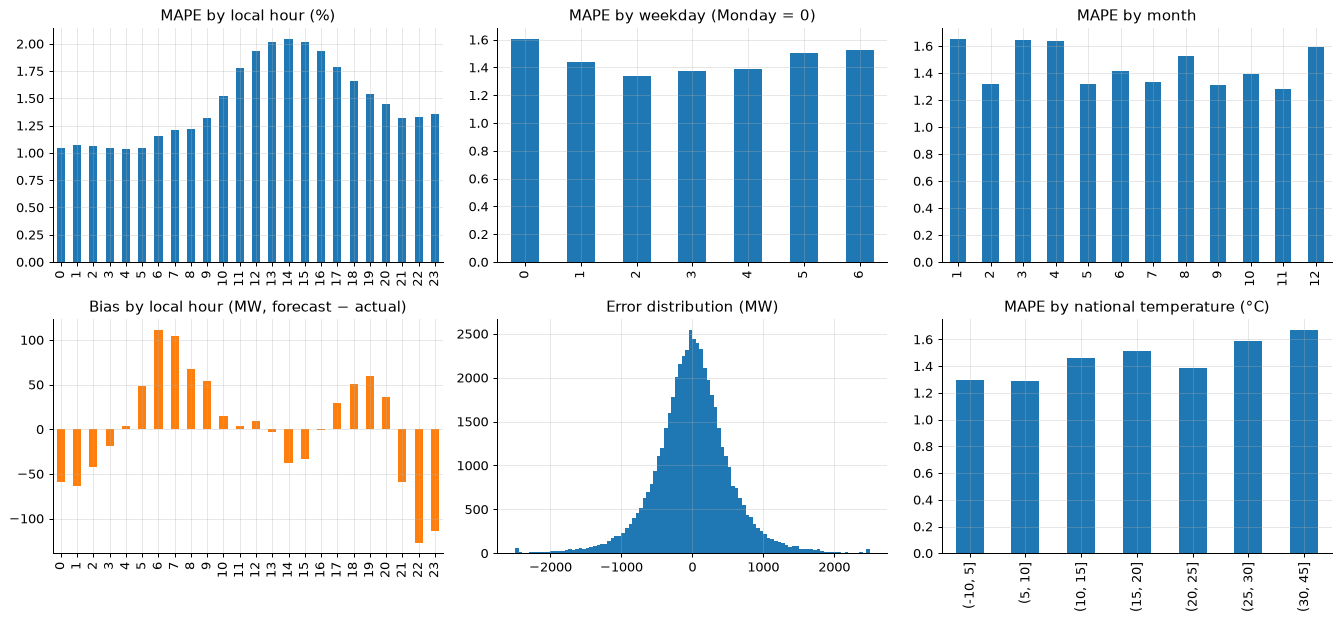

                     hours  MAE_MW  RMSE_MW  MAPE_%  bias_MW
ordinary weekday 29,904.00  389.77   542.63    1.35   -21.00
Saturday          6,096.00  371.29   506.79    1.47    83.02
Sunday            6,384.00  348.88   482.83    1.48    15.95
August            4,272.00  427.28   571.83    1.52    40.25
Christmas period  1,296.00  494.74   660.29    1.88    15.17
regional holiday  1,680.00  506.96   695.59    1.98   131.09
bridge day          240.00  521.19   680.86    1.99   -85.37
national holiday  1,200.00  519.62   710.79    2.20  -250.24

error quantiles (MW): 5% -860, 25% -289, 50% 2, 75% 295, 95% 862;  excess kurtosis 5.7
day-to-day correlation of REE's mean daily error: 0.315  at 7 days: 0.024
correlation of REE errors between hours of the same day: 1 h apart 0.91, 6 h apart 0.46, 12 h apart 0.33


In [21]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
bk.groupby("local_hour")["ape"].mean().mul(100).plot.bar(ax=axes[0, 0], color="C0")
axes[0, 0].set(title="MAPE by local hour (%)", xlabel="")
bk.groupby("weekday")["ape"].mean().mul(100).plot.bar(ax=axes[0, 1], color="C0")
axes[0, 1].set(title="MAPE by weekday (Monday = 0)", xlabel="")
bk.groupby("month")["ape"].mean().mul(100).plot.bar(ax=axes[0, 2], color="C0")
axes[0, 2].set(title="MAPE by month", xlabel="")
bk.groupby("local_hour")["err"].mean().plot.bar(ax=axes[1, 0], color="C1")
axes[1, 0].set(title="Bias by local hour (MW, forecast − actual)", xlabel="")
axes[1, 1].hist(bk["err"].clip(-2500, 2500), bins=100, color="C0")
axes[1, 1].set(title="Error distribution (MW)")
tb = pd.cut(bk["temp_obs"], [-10, 5, 10, 15, 20, 25, 30, 45])
bk.groupby(tb, observed=True)["ape"].mean().mul(100).plot.bar(ax=axes[1, 2], color="C0")
axes[1, 2].set(title="MAPE by national temperature (°C)", xlabel="")
fig.tight_layout()
fig.savefig(FIG / "eda_ree_errors.png", bbox_inches="tight")
plt.show()

cat = np.select([bk["holiday_national"], bk["holiday_intensity"] >= 0.05, bk["bridge_intensity"] >= 0.5,
                 bk["christmas"], bk["august"], bk["weekday"] == 5, bk["weekday"] == 6],
                ["national holiday", "regional holiday", "bridge day", "Christmas period", "August",
                 "Saturday", "Sunday"], "ordinary weekday")
print(bk.groupby(cat).apply(scores, include_groups=False).sort_values("MAPE_%").round(2).to_string())
e = bk["err"]
print(f"\nerror quantiles (MW): 5% {e.quantile(.05):.0f}, 25% {e.quantile(.25):.0f}, 50% {e.quantile(.5):.0f}, "
      f"75% {e.quantile(.75):.0f}, 95% {e.quantile(.95):.0f};  excess kurtosis {e.kurt():.1f}")
de = bk.groupby("local_date")["err"].mean()
print("day-to-day correlation of REE's mean daily error:", round(de.autocorr(1), 3), " at 7 days:", round(de.autocorr(7), 3))
hh = bk.pivot_table(index="local_date", columns="local_hour", values="err")
print("correlation of REE errors between hours of the same day: 1 h apart "
      f"{np.mean([hh[i].corr(hh[i + 1]) for i in range(23)]):.2f}, 6 h apart "
      f"{np.mean([hh[i].corr(hh[i + 6]) for i in range(18)]):.2f}, 12 h apart "
      f"{np.mean([hh[i].corr(hh[i + 12]) for i in range(12)]):.2f}")

## 12. Weather forecasts against observed weather

`temp_fc1` and `temp_fc2` are the population-weighted temperature as forecast one and two days
before each hour (Open-Meteo previous-runs archive). `temp_obs` is the reanalysis.

Share of hours with an archived forecast, by year:
      temp_fc1  temp_fc2
year                    
2021      0.78      0.77
2022      1.00      1.00
2023      0.99      0.99
2024      0.95      0.95
2025      1.00      1.00
2026      1.00      1.00
temp_fc1: first available 2021-03-24
temp_fc2: first available 2021-03-25

Days from 2022 with missing 2-day-lead forecasts: 22
 days  hours      start        end
   22    516 2023-12-30 2024-01-20

National temperature forecast error against reanalysis (°C):
            MAE                   bias            
     lead 1 day lead 2 days lead 1 day lead 2 days
year                                              
2021       1.11        1.15       0.98        1.02
2022       1.18        1.22       1.02        1.03
2023       1.21        1.23       0.92        0.91
2024       0.66        0.65       0.43        0.32
2025       0.52        0.54       0.21        0.13
2026       0.52        0.54       0.01       -0.04

Other forecast variables (rad

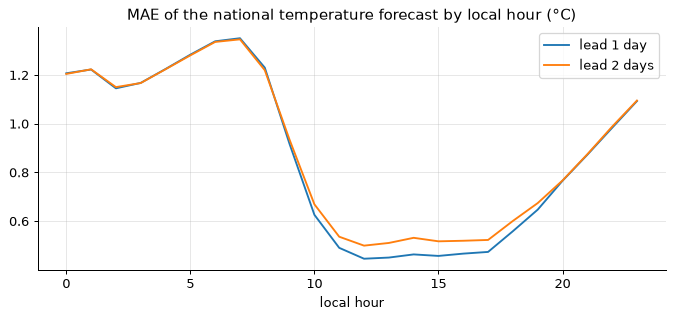

In [22]:
fc = df[["local_date", "year", "local_hour", "temp_obs", "temp_fc1", "temp_fc2", "rad_obs", "rad_fc2"]]
cov = fc.groupby("year")[["temp_fc1", "temp_fc2"]].agg(lambda s: s.notna().mean()).round(3)
print("Share of hours with an archived forecast, by year:")
print(cov.to_string())
for col in ("temp_fc1", "temp_fc2"):
    have = fc[col].notna()
    print(f"{col}: first available {fc.loc[have, 'local_date'].min().date()}")
missing_days = fc[(fc["local_date"] >= "2022-01-01") & fc["temp_fc2"].isna()].groupby("local_date").size()
print(f"\nDays from 2022 with missing 2-day-lead forecasts: {len(missing_days)}")
if len(missing_days):
    runs = (missing_days.index.to_series().diff() != pd.Timedelta(days=1)).cumsum()
    print(missing_days.groupby(runs.values).agg(["size", "sum"]).assign(
        start=missing_days.index.to_series().groupby(runs.values).min().values,
        end=missing_days.index.to_series().groupby(runs.values).max().values).rename(
        columns={"size": "days", "sum": "hours"}).to_string(index=False))
err = pd.DataFrame({"lead 1 day": (fc["temp_fc1"] - fc["temp_obs"]), "lead 2 days": (fc["temp_fc2"] - fc["temp_obs"])})
print("\nNational temperature forecast error against reanalysis (°C):")
print(pd.DataFrame({"MAE": err.abs().groupby(fc["year"]).mean().stack(), "bias": err.groupby(fc["year"]).mean().stack()})
      .unstack().round(2).to_string())
print("\nOther forecast variables (radiation, humidity, cloud, wind): first available",
      df.loc[df["rad_fc2"].notna(), "local_date"].min().date())
fig, ax = plt.subplots(figsize=(9, 3.5))
err.abs().groupby(fc["local_hour"]).mean().plot(ax=ax)
ax.set(title="MAE of the national temperature forecast by local hour (°C)", xlabel="local hour")
fig.savefig(FIG / "eda_weather_forecast_error.png", bbox_inches="tight")
plt.show()

## 13. Conclusions

**Data quality**

- The table is complete: 51,120 hours, no missing demand, no missing REE forecast.
- ESIOS switched the demand series from 10-minute to 5-minute values on 23 May 2022. Hourly means
  are unaffected.
- Outside the blackout, demand stays between 16.1 GW (Christmas night 2022) and 41.8 GW (8 January
  2021, the Filomena cold spell). The 15–45 GW plausibility range holds.
- Five hours are flagged as spikes: three on the blackout day, one on 1 January 2021 and one on
  11 June 2026, when demand fell about 7 GW below REE's forecast in the evening. That day is in the
  test period and needs a decision (mask or keep) before any model is scored on it.

**The definition change (section 2) is the main finding.** From 11 December 2025 the published
demand includes estimated self-consumption, about 5.5% of demand on average and up to 5.8 GW at
midday. Subtracting REE's own estimate restores the old series with no visible jump, and it leaves
REE's forecast errors in MW unchanged, because the same quantity is removed from forecast and actual.
Without the correction, 11 of the 12 test months would be on a different definition from the training data.

**What drives demand**

- Weekly cycle: Saturdays are 11% and Sundays 16% below the Monday–Friday mean.
- Temperature: on ordinary working days the daily mean is flat between about 16 °C and 20 °C and
  rises on both sides, by about 590–640 MW per °C of cold and 670–710 MW per °C of heat. Sensible
  prior centres for the Bayesian model are $T_H \approx 16$ °C and $T_C \approx 20$ °C, slightly
  tighter than the 15 and 21 in the design document.
- Thermal inertia is real: an exponentially smoothed temperature with $\lambda \approx 0.6$ per day
  cuts the error of the simple hinge fit from 837 to 708 MW.
- Holidays: a national holiday on a weekday lowers daily demand by about 18%. Regional holidays
  scale roughly with population-weighted intensity, and below an intensity of 0.05 they are not
  detectable. Bridge days are about 9% lower (only 9 cases) and the Christmas period about 10%.

**Seasonality in the frequency domain (section 5)**

- The expected cycles are all there and nothing else is: the 25 strongest spectral peaks are all
  harmonics of the day, the week or the year, yearly side-peaks of the daily harmonics, or the trend.
- Daily harmonics carry 47% of the variance, weekly 22% and yearly 13%. Together the additive
  Fourier model explains 82% and leaves a residual of 1.8 GW.
- The yearly cycle is almost entirely **semi-annual**: the 6-month harmonic has an amplitude of
  1.9 GW against 0.4 GW for the 12-month one. Demand peaks twice a year, in winter and in summer,
  which is the V-shaped temperature response seen from another angle.
- The daily cycle needs few harmonics: 4 capture 47.0 of its 47.1 points. The weekly cycle needs
  about 6 (down to 28 h), because the weekend is a square-ish step.
- Yearly harmonics beyond the third are small but do not decay (the 45-day harmonic is as large
  as the 12-month one). With four years of data these mostly describe particular weather episodes
  and fixed-date holidays, not a repeatable cycle.
- Weekly side-peaks around the daily harmonics hold 3.8% of the variance, and yearly side-peaks
  are visible too: the shape of the day depends on the weekday and on the season. An additive
  model cannot represent that.

**Trend**

- The yearly level moves by less than 1 GW per year once temperature is accounted for
  (26.9 GW in 2021, 25.4 in 2023, 26.0 in 2025).
- The *shape* changes much more. Between 2021 and 2025, working-day demand fell by 2.7 GW at
  12:00–13:00 and rose by 0.8 GW at 20:00–21:00. The midday share in spring went from 1.10 to 1.03.
  Any trend term has to depend on the hour; a single level is not enough.

**Autocorrelation**

- After removing seasonal means the residual has a standard deviation of 1.3 GW and is strongly
  persistent: correlation 0.64 at 14 hours and 0.50 at 38 hours, the range of lead times of a
  forecast issued at 10:00. Recent demand is therefore informative for the whole target day.
- The partial autocorrelation is dominated by lags 1 and 2 (0.97 and −0.28), which supports an
  AR(2) error rather than the AR(1) in the design document.

**REE's forecast, the benchmark**

- MAPE 1.45% and MAE 396 MW over the whole period, essentially unbiased. For scale, "same hour
  one week earlier" gives 4.95%.
- It has become less accurate over time: 1.23% in 2021, 1.67% in 2025.
- It is weakest from 12:00 to 16:00 (about 2.0%, against 1.05% at night), which fits the growing
  and weather-dependent self-consumption, and on national holidays (2.2%).
- Errors have heavy tails (excess kurtosis 5.7) and are strongly correlated within a day (0.91
  between adjacent hours, 0.33 twelve hours apart). Joint modelling of the 24 hours has something to capture.

**Blackout.** 28 April 2025 is 37% below REE's forecast and 29 April 16% below. 30 April is 3% below,
within the range of ordinary bad days. Masking 28–29 April is enough.

**Weather forecasts**

- Archived temperature forecasts start on 24 March 2021 and have one gap, 30 December 2023 to
  20 January 2024. The other variables (radiation, humidity, cloud, wind) only start on 20 January 2024.
- The archive is not homogeneous. Until the end of 2023 the forecast runs about 1 °C warmer than the
  reanalysis (MAE 1.1–1.2 °C); from 2024 the bias is small and the MAE about 0.5–0.65 °C. A model
  trained on forecast temperatures would see that step as a change in the temperature response.

### Decisions and recommendations for the next milestones

1. Target: `demand_mw`, the pre-change definition (grid demand net of self-consumption).
2. Blackout mask: 28–29 April 2025, as already configured.
3. Trend: use trailing means *by hour* over a few weeks plus the lagged demand, not a 365-day mean.
   This also removes the need for a year of warm-up after the 2021 start.
4. Train on observed (reanalysis) weather. For the realistic experiment, feed forecast weather at
   prediction time for validation and test, where the archive is homogeneous; do not train on the
   2021–2023 forecast temperatures without correcting their bias.
5. Bayesian model: AR(2) errors; priors centred on 16 °C and 20 °C; smoothing parameter near 0.6 per day.
6. Fourier orders: daily $K = 4$–6, weekly $K = 6$, yearly $K = 2$–3. Leave the rest of the yearly
   variation to temperature and holiday features, and let the daily profile depend on day type and season.
7. Open: whether to mask 11 June 2026 in the test period.